# Estudo de Ablação — Evolução Diferencial (DE)

Este notebook analisa os resultados gerados por `scripts/run_de_ablation.py` (`results/de_ablation/ablation.csv`) para responder **qual é a melhor configuração da Evolução Diferencial** no problema de ponderação de ensembles sob concept drift:
1. **Grade completa**: 8 estratégias DE (`rand/1`, `best/1`, `current-to-best/1`, `rand/2` × `bin`, `exp`) × 6 estratégias pós-drift (`S1..S6`);
2. **Testes estatísticos** (Friedman + Nemenyi com Diagrama CD e Wilcoxon pareado + Holm + $\hat{A}_{12}$);
3. **Desempenho por tipo de drift** (Recorrente, Novo, Incremental e Real);
4. **Ablação de hiperparâmetros**: `F` / `dither`, `CR`, `pop_size` e `hyper_sigma` (em S4).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.stats import a12, a12_label, cd_diagram, friedman_nemenyi, holm, wilcoxon_p

RESULTS_DIR = PROJECT_ROOT / "results" / "de_ablation"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

df = pd.read_csv(RESULTS_DIR / "ablation.csv")
strat_df = df[df["block"] == "strategies"].copy()
param_df = df[df["block"] == "params"].copy()

print(f"Total de execuções: {len(df)} (strategies={len(strat_df)}, params={len(param_df)})")
print("Datasets:", sorted(df["dataset"].unique()))
print("Sementes:", df["seed"].nunique())
print("Estratégias DE:", sorted(strat_df["de_strategy"].unique()))

Total de execuções: 21960 (strategies=8640, params=13320)
Datasets: ['AGR-Abr', 'AGR-Grad', 'Elec2', 'RBF-Inc', 'SEA-Rec', 'STAGGER-Rec']
Sementes: 30
Estratégias DE: ['best/1/bin', 'best/1/exp', 'current-to-best/1/bin', 'current-to-best/1/exp', 'rand/1/bin', 'rand/1/exp', 'rand/2/bin', 'rand/2/exp']


## 1. Heatmap e Ranking: Estratégia DE × Estratégia Pós-Drift (S1–S6)

post_drift,S1,S2,S3,S4,S5,S6,Média
de_strategy,,,,,,,
rand/2/bin,0.8708,0.8656,0.8714,0.8714,0.8675,0.8709,0.8696
rand/2/exp,0.8707,0.8672,0.8708,0.8699,0.8653,0.8702,0.8690
rand/1/exp,0.8716,0.8575,0.8704,0.8716,0.8577,0.8720,0.8668
rand/1/bin,0.8713,0.8587,0.8700,0.8716,0.8575,0.8705,0.8666
current-to-best/1/exp,0.8731,0.8406,0.8691,0.8735,0.8441,0.8715,0.8620
current-to-best/1/bin,0.8694,0.8443,0.8670,0.8713,0.8448,0.8690,0.8610
best/1/exp,0.8729,0.8350,0.8684,0.8714,0.8382,0.8696,0.8593
best/1/bin,0.8715,0.8338,0.8677,0.8717,0.8341,0.8673,0.8577


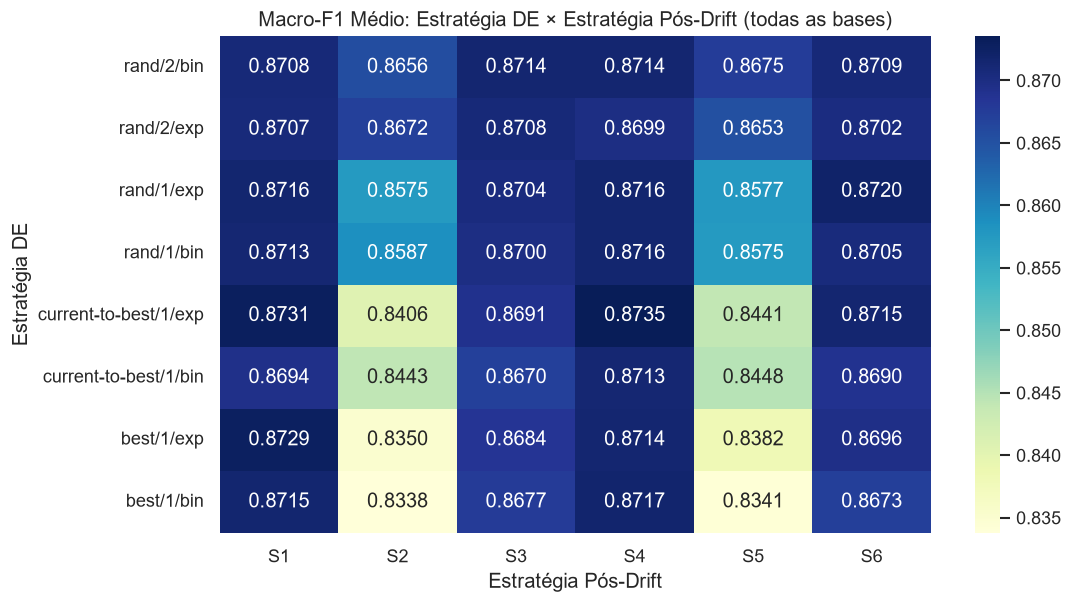

=== Top 12 Combinações (Estratégia DE + Pós-Drift) ===


macro_f1    n_evals  gens_to_95  \
de_strategy           post_drift                                    
current-to-best/1/exp S4            0.8735  4594.8333     12.4768   
                      S1            0.8731  4647.3333     14.6249   
best/1/exp            S1            0.8729  3377.3333      7.7435   
rand/1/exp            S6            0.8720  5167.0000     19.3142   
best/1/bin            S4            0.8717  3871.0000      9.9406   
rand/1/exp            S1            0.8716  5682.8333     21.0405   
                      S4            0.8716  5088.0000     15.7225   
rand/1/bin            S4            0.8716  5229.1667     16.2287   
best/1/bin            S1            0.8715  3101.8333      6.0614   
current-to-best/1/exp S6            0.8715  4333.5000     13.5892   
best/1/exp            S4            0.8714  4080.8333     10.9656   
rand/2/bin            S4            0.8714  4990.8333     14.8150   

                                  replay_time_s  
de_strategy           post_drift                 
current-to-best/1/exp S4                 0.4359  
                      S1                 0.4402  
best/1/exp            S1                 0.3416  
rand/1/exp            S6                 0.4812  
best/1/bin            S4                 0.3621  
rand/1/exp            S1                 0.5110  
                      S4                 0.4676  
rand/1/bin            S4                 0.4664  
best/1/bin            S1                 0.3046  
current-to-best/1/exp S6                 0.4120  
best/1/exp            S4                 0.3966  
rand/2/bin            S4                 0.4438

In [2]:
piv_grid = strat_df.groupby(["de_strategy", "post_drift"])["macro_f1"].mean().unstack()
piv_grid["Média"] = piv_grid.mean(axis=1)
piv_grid = piv_grid.sort_values("Média", ascending=False)
display(piv_grid.round(4))

fig, ax = plt.subplots(figsize=(9.5, 5.2))
sns.heatmap(piv_grid.drop(columns=["Média"]), annot=True, fmt=".4f", cmap="YlGnBu", ax=ax)
ax.set_title("Macro-F1 Médio: Estratégia DE × Estratégia Pós-Drift (todas as bases)")
ax.set_xlabel("Estratégia Pós-Drift")
ax.set_ylabel("Estratégia DE")
fig.tight_layout()
fig.savefig(FIG_DIR / "heatmap_de_x_postdrift.png", dpi=150)
plt.show()

# Top 12 combinações (de_strategy + post_drift)
combos = strat_df.groupby(["de_strategy", "post_drift"])[["macro_f1", "n_evals", "gens_to_95", "replay_time_s"]].mean()
combos = combos.sort_values("macro_f1", ascending=False)
print("=== Top 12 Combinações (Estratégia DE + Pós-Drift) ===")
display(combos.head(12).round(4))

## 2. Testes Estatísticos entre as 8 Estratégias DE (Friedman + Nemenyi e Wilcoxon + Holm + $\hat{A}_{12}$)

=== 8 Estratégias DE (todas S1–S6, N=1080 blocos) ===
Friedman p = 3.213e-69 | CD = 0.319


,Rank Médio
de_strategy,
rand/2/exp,3.997222
rand/1/exp,4.015741
rand/2/bin,4.079630
rand/1/bin,4.156481
current-to-best/1/exp,4.464815
current-to-best/1/bin,4.999074
best/1/exp,5.040741
best/1/bin,5.246296


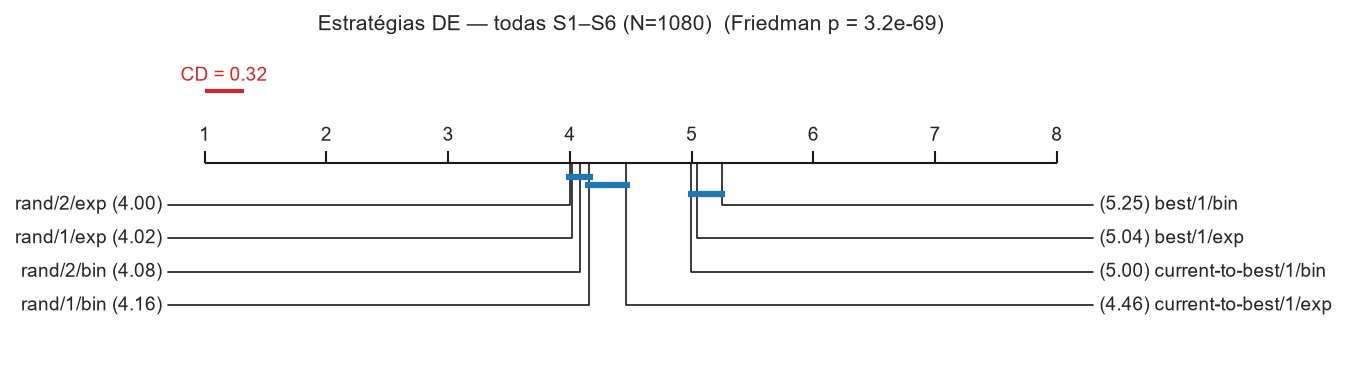


=== 8 Estratégias DE em S4 (N=180 blocos) ===
Friedman p = 0.0113 | CD = 0.783


,Rank Médio
de_strategy,
current-to-best/1/exp,3.955556
rand/1/exp,4.288889
rand/1/bin,4.338889
current-to-best/1/bin,4.566667
best/1/bin,4.616667
best/1/exp,4.633333
rand/2/bin,4.694444
rand/2/exp,4.905556


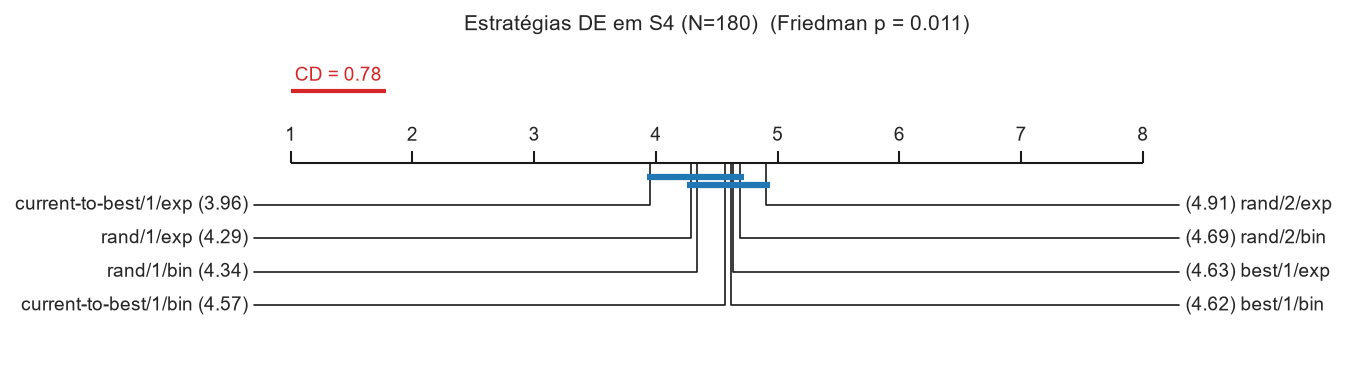

In [3]:
# 2a) Friedman + Nemenyi sobre todas as 8 estratégias DE (blocos = dataset x seed x post_drift)
piv_all = strat_df.pivot_table(
    index=["dataset", "seed", "post_drift"], columns="de_strategy", values="macro_f1"
).dropna()
fr_all = friedman_nemenyi(piv_all)
print(f"=== 8 Estratégias DE (todas S1–S6, N={fr_all['N']} blocos) ===")
print(f"Friedman p = {fr_all['p_value']:.4g} | CD = {fr_all['cd']:.3f}")
display(fr_all["avg_ranks"].to_frame("Rank Médio"))
p1 = FIG_DIR / "cd_de_strategies_all.png"
cd_diagram(fr_all["avg_ranks"], fr_all["cd"], f"Estratégias DE — todas S1–S6 (N={fr_all['N']})", str(p1), fr_all["p_value"])
display(Image(filename=str(p1)))

# 2b) Friedman + Nemenyi fixando apenas na melhor estratégia pós-drift global
best_post = strat_df.groupby("post_drift")["macro_f1"].mean().idxmax()
piv_bp = strat_df[strat_df["post_drift"] == best_post].pivot_table(
    index=["dataset", "seed"], columns="de_strategy", values="macro_f1"
).dropna()
fr_bp = friedman_nemenyi(piv_bp)
print(f"\n=== 8 Estratégias DE em {best_post} (N={fr_bp['N']} blocos) ===")
print(f"Friedman p = {fr_bp['p_value']:.4g} | CD = {fr_bp['cd']:.3f}")
display(fr_bp["avg_ranks"].to_frame("Rank Médio"))
p2 = FIG_DIR / f"cd_de_strategies_{best_post}.png"
cd_diagram(fr_bp["avg_ranks"], fr_bp["cd"], f"Estratégias DE em {best_post} (N={fr_bp['N']})", str(p2), fr_bp["p_value"])
display(Image(filename=str(p2)))

In [4]:
# Wilcoxon pareado + Holm + Â12: melhor estratégia DE vs demais (usando best_post)
best_de_strat = fr_bp["avg_ranks"].index[0]
others = [c for c in piv_bp.columns if c != best_de_strat]
print(f"Melhor estratégia DE em {best_post}: {best_de_strat}")

w_rows = []
for ds in sorted(strat_df["dataset"].unique()):
    sub = strat_df[(strat_df["dataset"] == ds) & (strat_df["post_drift"] == best_post)].pivot_table(
        index="seed", columns="de_strategy", values="macro_f1"
    ).dropna()
    pvals = [wilcoxon_p(sub[best_de_strat], sub[o]) for o in others]
    padj = holm(pvals)
    for o, p, pa in zip(others, pvals, padj):
        e = a12(sub[best_de_strat], sub[o])
        diff = float(sub[best_de_strat].mean() - sub[o].mean())
        res = "=" if pa >= 0.05 else ("+" if diff > 0 else "−")
        w_rows.append({
            "dataset": ds, "comparação": f"{best_de_strat} vs {o}",
            "Δ macro-F1": diff, "p (Holm)": pa, "Â12": e, "efeito": a12_label(e), "resultado": res,
        })

wdf = pd.DataFrame(w_rows)
wl = wdf.groupby("comparação")["resultado"].apply(
    lambda r: f"{(r == '+').sum()}/{(r == '=').sum()}/{(r == '−').sum()}"
).to_frame("Vitórias / Empates / Derrotas")
display(wl)
display(wdf)

Melhor estratégia DE em S4: current-to-best/1/exp


,Vitórias / Empates / Derrotas
comparação,
current-to-best/1/exp vs best/1/bin,0/6/0
current-to-best/1/exp vs best/1/exp,0/6/0
current-to-best/1/exp vs current-to-best/1/bin,0/6/0
current-to-best/1/exp vs rand/1/bin,0/6/0
current-to-best/1/exp vs rand/1/exp,0/6/0
current-to-best/1/exp vs rand/2/bin,0/6/0
current-to-best/1/exp vs rand/2/exp,0/6/0


,dataset,comparação,Δ macro-F1,p (Holm),Â12,efeito,resultado
0,AGR-Abr,current-to-best/1/exp vs best/1/bin,0.005890,0.595383,0.561111,pequeno,=
1,AGR-Abr,current-to-best/1/exp vs best/1/exp,0.006477,0.914211,0.541111,desprezível,=
2,AGR-Abr,current-to-best/1/exp vs current-to-best/1/bin,0.008499,1.000000,0.565556,pequeno,=
3,AGR-Abr,current-to-best/1/exp vs rand/1/bin,0.009218,0.551698,0.564444,pequeno,=
4,AGR-Abr,current-to-best/1/exp vs rand/1/exp,0.005972,1.000000,0.533333,desprezível,=
5,AGR-Abr,current-to-best/1/exp vs rand/2/bin,0.008422,1.000000,0.531111,desprezível,=
6,AGR-Abr,current-to-best/1/exp vs rand/2/exp,0.011269,0.255045,0.575556,pequeno,=
7,AGR-Grad,current-to-best/1/exp vs best/1/bin,0.001459,1.000000,0.541111,desprezível,=
8,AGR-Grad,current-to-best/1/exp vs best/1/exp,0.004086,0.841698,0.585556,pequeno,=
9,AGR-Grad,current-to-best/1/exp vs current-to-best/1/bin,0.000329,1.000000,0.517778,desprezível,=


## 3. Desempenho das Estratégias DE por Base e por Tipo de Drift

de_strategy,best/1/bin,best/1/exp,current-to-best/1/bin,current-to-best/1/exp,rand/1/bin,rand/1/exp,rand/2/bin,rand/2/exp
dataset,,,,,,,,
AGR-Abr,0.8754,0.8748,0.8728,0.8813,0.8721,0.8753,0.8729,0.8700
AGR-Grad,0.8745,0.8718,0.8756,0.8759,0.8756,0.8708,0.8759,0.8704
Elec2,0.8687,0.8692,0.8694,0.8693,0.8688,0.8695,0.8687,0.8690
RBF-Inc,0.9091,0.9090,0.9089,0.9094,0.9088,0.9095,0.9084,0.9089
SEA-Rec,0.8556,0.8555,0.8548,0.8556,0.8548,0.8549,0.8540,0.8544
STAGGER-Rec,0.8471,0.8481,0.8465,0.8498,0.8494,0.8497,0.8485,0.8464
Média Geral,0.8717,0.8714,0.8713,0.8735,0.8716,0.8716,0.8714,0.8699


=== Macro-F1 por Tipo de Drift ===


de_strategy,best/1/bin,best/1/exp,current-to-best/1/bin,current-to-best/1/exp,rand/1/bin,rand/1/exp,rand/2/bin,rand/2/exp
"Recorrente (SEA, STAGGER)",0.8513,0.8518,0.8506,0.8527,0.8521,0.8523,0.8513,0.8504
"Novo (AGR-Abr, AGR-Grad)",0.8749,0.8733,0.8742,0.8786,0.8738,0.8731,0.8744,0.8702
Incremental (RBF-Inc),0.9091,0.9090,0.9089,0.9094,0.9088,0.9095,0.9084,0.9089
Real (Elec2),0.8687,0.8692,0.8694,0.8693,0.8688,0.8695,0.8687,0.8690


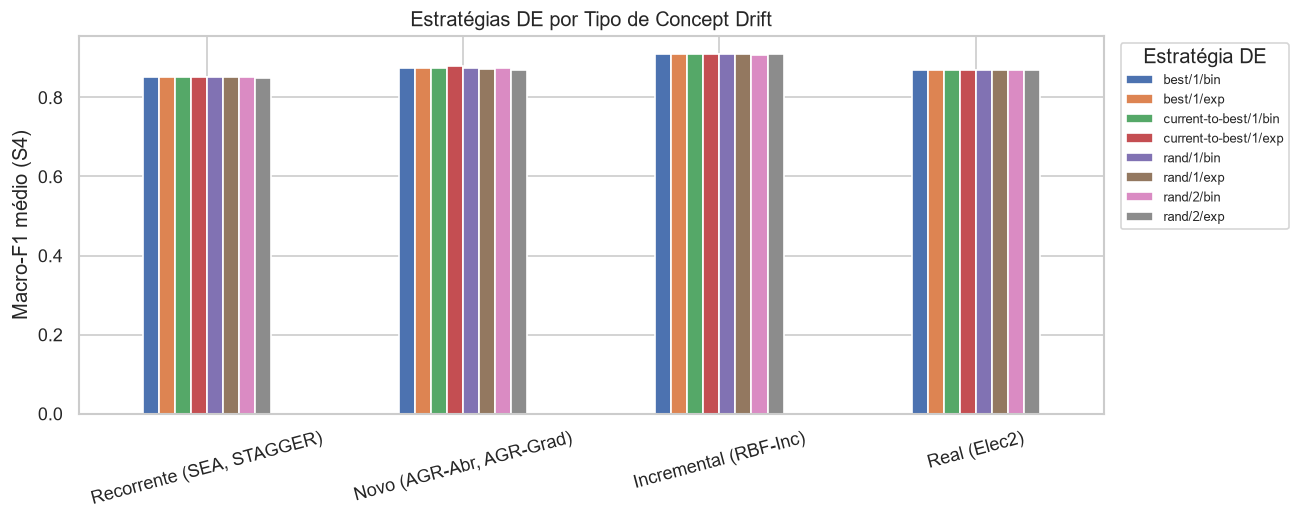

In [5]:
# Macro-F1 por base para cada estratégia DE (na melhor estratégia pós-drift)
by_ds = strat_df[strat_df["post_drift"] == best_post].groupby(["dataset", "de_strategy"])["macro_f1"].mean().unstack()
by_ds.loc["Média Geral"] = by_ds.mean()
display(by_ds.round(4))

# Agrupamento por tipo de drift
GROUPS = {
    "Recorrente (SEA, STAGGER)": ["SEA-Rec", "STAGGER-Rec"],
    "Novo (AGR-Abr, AGR-Grad)": ["AGR-Abr", "AGR-Grad"],
    "Incremental (RBF-Inc)": ["RBF-Inc"],
    "Real (Elec2)": ["Elec2"],
}
g_rows = {}
for gname, dss in GROUPS.items():
    sub_g = strat_df[(strat_df["post_drift"] == best_post) & (strat_df["dataset"].isin(dss))]
    if not sub_g.empty:
        g_rows[gname] = sub_g.groupby("de_strategy")["macro_f1"].mean()
g_df = pd.DataFrame(g_rows).T
print("=== Macro-F1 por Tipo de Drift ===")
display(g_df.round(4))

fig, ax = plt.subplots(figsize=(11, 4.5))
g_df.plot(kind="bar", ax=ax)
ax.set_ylabel(f"Macro-F1 médio ({best_post})")
ax.set_xlabel("")
ax.set_title("Estratégias DE por Tipo de Concept Drift")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Estratégia DE", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "de_by_drift_type.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Ablação de Hiperparâmetros do DE (`F`/dither, `CR`, `pop_size` e `hyper_sigma`)


=== Ablação: F ===


macro_f1    n_evals  gens_to_95  div_end
de_strategy           ablation_value                                          
current-to-best/1/bin 0.3               0.8690  4325.0556     13.3736   0.0793
                      0.5               0.8699  4112.1111     12.2398   0.0554
                      0.8               0.8714  4278.5556     11.7987   0.0819
                      dither            0.8715  4323.8889     12.3259   0.0716
rand/1/bin            0.3               0.8712  5323.1111     18.8463   0.0789
                      0.5               0.8711  5464.0000     19.1341   0.1145
                      0.8               0.8700  5000.5556     16.8972   0.1764
                      dither            0.8700  5062.1667     17.3328   0.1633


=== Ablação: CR ===


macro_f1    n_evals  gens_to_95  div_end
de_strategy           ablation_value                                          
current-to-best/1/bin 0.3               0.8729  4956.5556     16.6293   0.1546
                      0.5               0.8726  4771.5556     14.8181   0.1093
                      0.7               0.8725  4441.7222     13.5018   0.0785
                      0.9               0.8699  4112.1111     12.2398   0.0554
rand/1/bin            0.3               0.8719  5094.5556     17.4758   0.2099
                      0.5               0.8716  5117.5556     17.2799   0.1662
                      0.7               0.8721  5144.7778     17.3561   0.1420
                      0.9               0.8711  5464.0000     19.1341   0.1145


=== Ablação: pop_size ===


macro_f1    n_evals  gens_to_95  div_end
de_strategy           ablation_value                                          
current-to-best/1/bin 15                0.8692  2078.9167     11.8997   0.0505
                      30                0.8699  4112.1111     12.2398   0.0554
                      50                0.8726  6692.9630     11.2802   0.0586
rand/1/bin            15                0.8697  2679.7222     19.2227   0.0932
                      30                0.8711  5464.0000     19.1341   0.1145
                      50                0.8706  8850.4630     18.2201   0.1324


=== Ablação: hyper_sigma ===


macro_f1    n_evals  gens_to_95  div_end
de_strategy           ablation_value                                          
current-to-best/1/bin 0.0               0.8585  3176.8333      8.6800   0.0301
                      0.1               0.8734  4300.3333     11.6735   0.0752
                      0.25              0.8713  4372.8333     12.1287   0.0929
                      0.5               0.8720  4483.6667     12.1472   0.1039
rand/1/bin            0.0               0.8652  5233.0000     20.1756   0.0843
                      0.1               0.8722  5452.5000     17.6733   0.1282
                      0.25              0.8716  5229.1667     16.2287   0.1426
                      0.5               0.8708  4967.3333     14.4550   0.1707

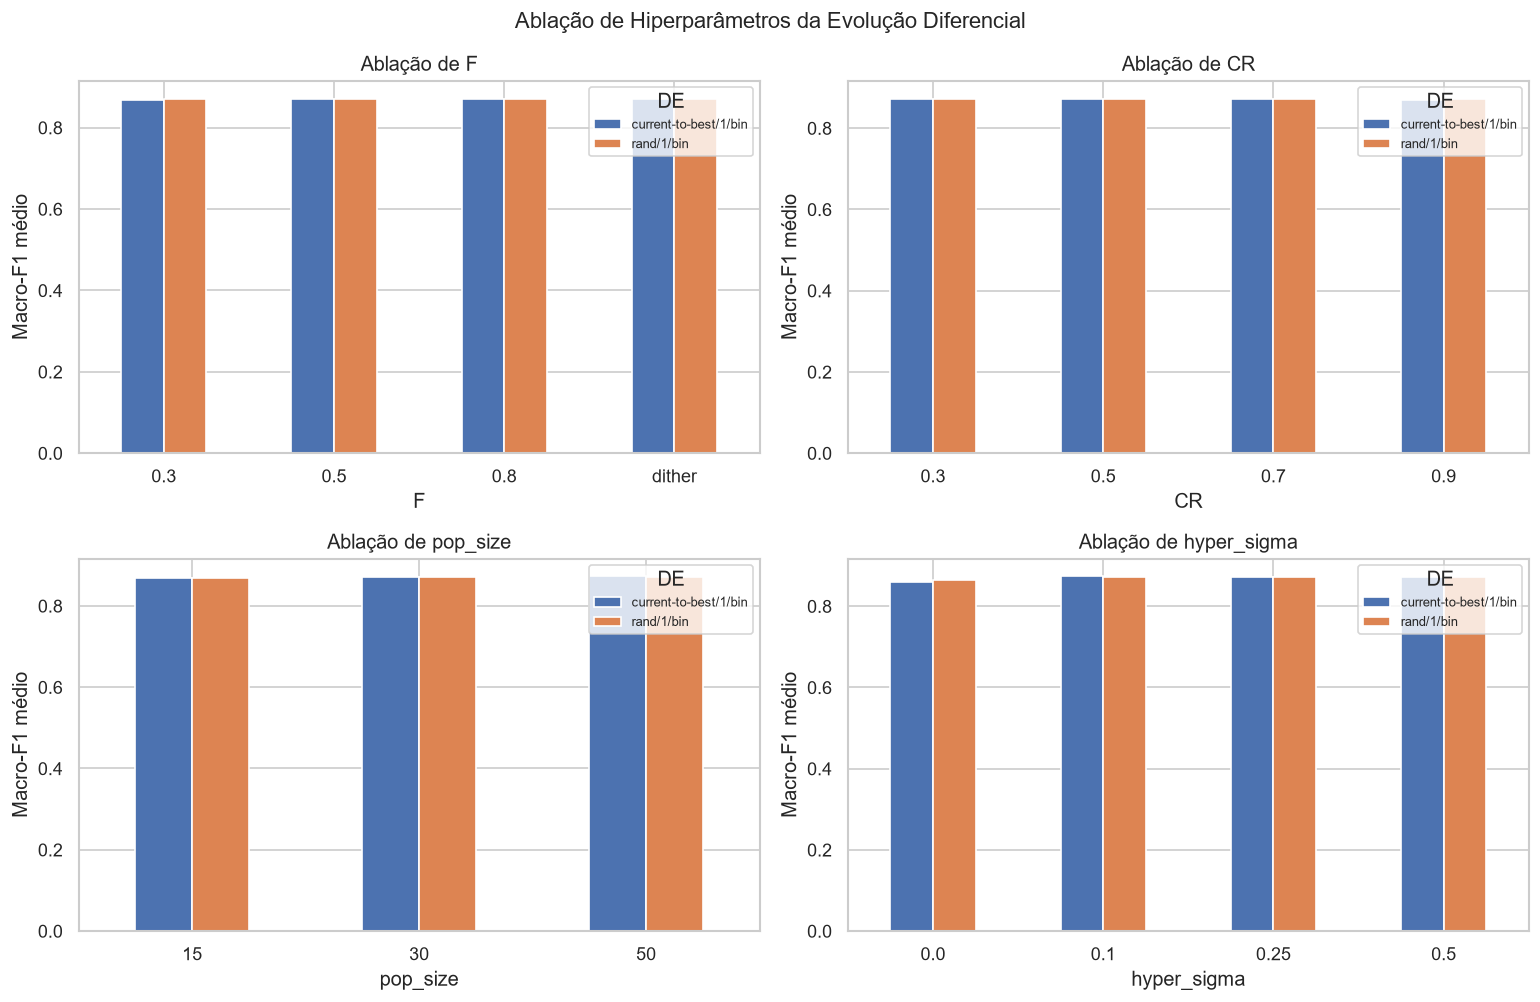

In [6]:
if not param_df.empty:
    factors = ["F", "CR", "pop_size", "hyper_sigma"]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
    for ax, fac in zip(axes.flat, factors):
        sub_f = param_df[param_df["ablation_factor"] == fac]
        if sub_f.empty:
            ax.axis("off")
            continue
        tab = sub_f.groupby(["ablation_value", "de_strategy"])["macro_f1"].mean().unstack()
        print(f"\n=== Ablação: {fac} ===")
        display(sub_f.groupby(["de_strategy", "ablation_value"])[["macro_f1", "n_evals", "gens_to_95", "div_end"]].mean().round(4))
        tab.plot(kind="bar", ax=ax)
        ax.set_title(f"Ablação de {fac}")
        ax.set_xlabel(fac)
        ax.set_ylabel("Macro-F1 médio")
        ax.tick_params(axis="x", rotation=0)
        ax.legend(title="DE", fontsize=8)
    fig.suptitle("Ablação de Hiperparâmetros da Evolução Diferencial", fontsize=13)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "ablation_params.png", dpi=150)
    plt.show()
else:
    print("Bloco 'params' não presente em ablation.csv.")